<a href="https://colab.research.google.com/github/JacekDrzycimski/6tunnel/blob/master/Simple_inst_enc_comms_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simple Encrypted Instant Communicator
This notebook demonstrates a simple, end-to-end encrypted instant messenger interface. We use symmetric **Fernet encryption** (AES-128 in CBC mode with HMAC-SHA256) to encrypt and decrypt messages, and **Gradio** to build the GUI.

In [1]:
!pip install -q cryptography gradio

In [2]:
import os
import gradio as gr
from cryptography.fernet import Fernet
import base64
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives.kdf.pbkdf2 import PBKDF2HMAC

def generate_key_from_password_dynamic(password: str, salt: bytes) -> bytes:
    kdf = PBKDF2HMAC(
        algorithm=hashes.SHA256(),
        length=32,
        salt=salt,
        iterations=100000
    )
    return base64.urlsafe_b64encode(kdf.derive(password.encode()))

def encrypt_message_dynamic(message: str, password: str) -> str:
    if not message or not password:
        return "Error: Message and Password are required!"
    try:
        salt = os.urandom(16)
        key = generate_key_from_password_dynamic(password, salt)
        fernet = Fernet(key)
        encrypted_bytes = fernet.encrypt(message.encode())
        combined_payload = salt + encrypted_bytes
        return base64.b64encode(combined_payload).decode('utf-8')
    except Exception as e:
        return f"Encryption failed: {str(e)}"

def decrypt_message_dynamic(encrypted_payload_b64: str, password: str) -> str:
    if not encrypted_payload_b64 or not password:
        return "Error: Encrypted payload and Password are required!"
    try:
        combined_payload = base64.b64decode(encrypted_payload_b64.encode('utf-8'))
        salt = combined_payload[:16]
        encrypted_bytes = combined_payload[16:]
        key = generate_key_from_password_dynamic(password, salt)
        fernet = Fernet(key)
        decrypted_bytes = fernet.decrypt(encrypted_bytes)
        return decrypted_bytes.decode()
    except Exception as e:
        return "Decryption failed: Invalid password or corrupted message."

# Building the Gradio interface using the secure functions
with gr.Blocks() as demo:
    gr.Markdown("# 🔐 Secure Encrypted Instant Communicator (Dynamic Salts)")
    gr.Markdown("This version uses a cryptographically secure random 16-byte salt for every message, preventing replay and dictionary attacks!")

    with gr.Tab("Encrypt (Sender)"):
        msg_input = gr.Textbox(label="Plaintext Message", placeholder="Type your secret message here...", lines=3)
        pass_encrypt = gr.Textbox(label="Secret Passphrase", placeholder="e.g., my_secret_key", type="password")
        encrypt_btn = gr.Button("Encrypt 🔒", variant="primary")
        encrypted_output = gr.Textbox(label="Encrypted Payload (Safe to send over public channels)", lines=3)

        encrypt_btn.click(encrypt_message_dynamic, inputs=[msg_input, pass_encrypt], outputs=encrypted_output)

    with gr.Tab("Decrypt (Receiver)"):
        cipher_input = gr.Textbox(label="Encrypted Payload", placeholder="Paste the encrypted block here...", lines=3)
        pass_decrypt = gr.Textbox(label="Secret Passphrase", placeholder="Enter the shared passphrase", type="password")
        decrypt_btn = gr.Button("Decrypt 🔓", variant="secondary")
        decrypted_output = gr.Textbox(label="Decrypted Message", lines=3)

        decrypt_btn.click(decrypt_message_dynamic, inputs=[cipher_input, pass_decrypt], outputs=decrypted_output)

# Launching the interface inside Colab with the soft theme
demo.launch(inline=True, share=True, theme=gr.themes.Soft())

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9e150dae33e0a4f926.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Storing Encrypted History to a Local JSON File
Below is the code to create a simple history logger that automatically saves encrypted messages, timestamps, and metadata to a local JSON file (`message_history.json`).

In [4]:
import json
from datetime import datetime

HISTORY_FILE = 'message_history.json'

def save_message_to_history(sender_name: str, encrypted_payload: str):
    """Appends a new encrypted message entry to the local JSON file."""
    entry = {
        "timestamp": datetime.now().isoformat(),
        "sender": sender_name,
        "encrypted_payload": encrypted_payload
    }

    try:
        try:
            with open(HISTORY_FILE, 'r') as f:
                history = json.load(f)
        except (FileNotFoundError, json.JSONDecodeError):
            history = []

        history.append(entry)

        with open(HISTORY_FILE, 'w') as f:
            json.dump(history, f, indent=4)
        print(f"[Success] Message securely saved to {HISTORY_FILE}")
    except Exception as e:
        print(f"[Error] Could not save history: {e}")

def load_and_decrypt_history_paginated(password: str, page: int = 1, page_size: int = 5):
    """Loads the history and decrypts entries belonging to the specified page (1-indexed)."""
    try:
        with open(HISTORY_FILE, 'r') as f:
            history = json.load(f)
    except FileNotFoundError:
        print("No history file found yet.")
        return
    except json.JSONDecodeError:
        print("History file is corrupted.")
        return

    total_messages = len(history)
    total_pages = (total_messages + page_size - 1) // page_size if total_messages > 0 else 1

    # Ensure requested page is within valid range
    page = max(1, min(page, total_pages))

    # Calculate start and end indices
    start_idx = (page - 1) * page_size
    end_idx = min(start_idx + page_size, total_messages)

    paginated_slice = history[start_idx:end_idx]

    print(f"--- Decrypted Message History (Page {page} of {total_pages}, Showing items {start_idx + 1}-{end_idx} of {total_messages}) ---")
    for idx, entry in enumerate(paginated_slice, start=start_idx + 1):
        decrypted = decrypt_message_dynamic(entry["encrypted_payload"], password)
        print(f"[{idx}] Time: {entry['timestamp']} | Sender: {entry['sender']}")
        print(f"    Decrypted: {decrypted}\n")

# --- Quick Test of Saving & Loading History with Pagination ---
# Define fallback test values if they are not yet run or defined elsewhere in the notebook
if 'test_password' not in globals():
    test_password = "secure_password_123"
if 'ciphertext_1' not in globals():
    ciphertext_1 = encrypt_message_dynamic("This message now uses a dynamic salt!", test_password)

for i in range(12):
    save_message_to_history(f"User_{i}", ciphertext_1)

# Read back page 2 of the history (each page showing 5 items)
load_and_decrypt_history_paginated(test_password, page=2, page_size=5)

[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
[Success] Message securely saved to message_history.json
--- Decrypted Message History (Page 2 of 3, Showing items 6-10 of 12) ---
[6] Time: 2026-11-02T15:15:22.970328 | Sender: User_5
    Decrypted: This message now uses a dynamic salt!

[7] Time: 2026-11-02T15:15:22.970572 | Sender: User_6
    Decrypted: This message now uses a dynamic salt!

[8] Time: 2026-11-02T15:15

## Export Decrypted History to CSV
The following cell decrypts all messages stored in your database using your master password and outputs them into a standard CSV format (`decrypted_history.csv`) suitable for spreadsheet tools like Microsoft Excel or Google Sheets.

In [5]:
import pandas as pd
from google.colab import files

def export_history_to_csv(password: str, output_csv: str = 'decrypted_history.csv'):
    """Decrypts the local JSON history and saves it to a structured CSV file."""
    try:
        with open(HISTORY_FILE, 'r') as f:
            history = json.load(f)
    except FileNotFoundError:
        print("[Error] No history file found to export.")
        return
    except json.JSONDecodeError:
        print("[Error] History file is corrupted.")
        return

    decrypted_records = []
    for idx, entry in enumerate(history, 1):
        decrypted_msg = decrypt_message_dynamic(entry["encrypted_payload"], password)

        decrypted_records.append({
            "Index": idx,
            "Timestamp": entry.get("timestamp", ""),
            "Sender": entry.get("sender", ""),
            "Decrypted_Message": decrypted_msg
        })

    # Convert list of dicts to a Pandas DataFrame
    df = pd.DataFrame(decrypted_records)

    # Save to CSV locally
    df.to_csv(output_csv, index=False)
    print(f"[Success] Decrypted history exported to: {output_csv}")

    # Display preview
    display(df.head())

    # Trigger browser file download
    files.download(output_csv)

# Run the export function
export_history_to_csv(test_password)

[Success] Decrypted history exported to: decrypted_history.csv


,Index,Timestamp,Sender,Decrypted_Message
0,1,2026-11-02T15:15:22.968328,User_0,This message now uses a dynamic salt!
1,2,2026-11-02T15:15:22.968906,User_1,This message now uses a dynamic salt!
2,3,2026-11-02T15:15:22.969500,User_2,This message now uses a dynamic salt!
3,4,2026-11-02T15:15:22.969826,User_3,This message now uses a dynamic salt!
4,5,2026-11-02T15:15:22.970053,User_4,This message now uses a dynamic salt!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Keyword Search inside Exported CSV
Use the function below to search for specific terms or senders within the generated `decrypted_history.csv` file.

In [6]:
import pandas as pd

def search_history_csv(keyword: str, csv_path: str = 'decrypted_history.csv'):
    """Searches for a keyword in the Sender or Decrypted_Message columns of the exported CSV."""
    try:
        df = pd.read_csv(csv_path)
    except FileNotFoundError:
        print(f"[Error] CSV file '{csv_path}' not found. Please run the export cell first.")
        return

    # Case-insensitive search across Sender and Decrypted_Message columns
    query = keyword.lower()
    matches = df[
        df['Sender'].astype(str).str.lower().str.contains(query, na=False) |
        df['Decrypted_Message'].astype(str).str.lower().str.contains(query, na=False)
    ]

    print(f"--- Search Results for '{keyword}' ({len(matches)} matches found) ---")
    display(matches)

# --- Example Search: Find any messages sent by 'User_3' or containing 'salt' ---
search_history_csv("User_3")

--- Search Results for 'User_3' (1 matches found) ---


,Index,Timestamp,Sender,Decrypted_Message
3,4,2026-11-02T15:15:22.969826,User_3,This message now uses a dynamic salt!


### Encrypted Message History Statistics
Let's analyze the communication metadata (senders, timestamps, volume) stored in our encrypted history file using pandas.

In [8]:
import pandas as pd
import json

def summarize_history_stats(json_path='message_history.json'):
    try:
        # Load JSON history
        with open(json_path, 'r') as f:
            history = json.load(f)
    except FileNotFoundError:
        print(f"[Error] '{json_path}' not found.")
        return
    except json.JSONDecodeError:
        print(f"[Error] '{json_path}' is corrupted.")
        return

    # Convert to DataFrame
    df = pd.DataFrame(history)
    df['timestamp'] = pd.to_datetime(df['timestamp'])

    # Calculate key statistics
    total_messages = len(df)
    unique_senders = df['sender'].nunique()
    messages_per_sender = df['sender'].value_counts()

    first_message_time = df['timestamp'].min()
    last_message_time = df['timestamp'].max()

    print("===============================================")
    print("      ENCRYPTED MESSAGE HISTORY STATISTICS      ")
    print("===============================================")
    print(f"Total Encrypted Messages: {total_messages}")
    print(f"Unique Senders:           {unique_senders}")
    print(f"First Activity Recorded:  {first_message_time}")
    print(f"Latest Activity Recorded: {last_message_time}")
    print("-----------------------------------------------")
    print("Message Count per Sender:")
    display(messages_per_sender.to_frame(name='Message Count'))

# Run the summary
summarize_history_stats()

      ENCRYPTED MESSAGE HISTORY STATISTICS      
Total Encrypted Messages: 12
Unique Senders:           12
First Activity Recorded:  2026-11-02 15:15:22.968328
Latest Activity Recorded: 2026-11-02 15:15:22.972010
-----------------------------------------------
Message Count per Sender:


,Message Count
sender,
User_0,1
User_1,1
User_2,1
User_3,1
User_4,1
User_5,1
User_6,1
User_7,1
User_8,1


### Visualizing Message Volume per Sender

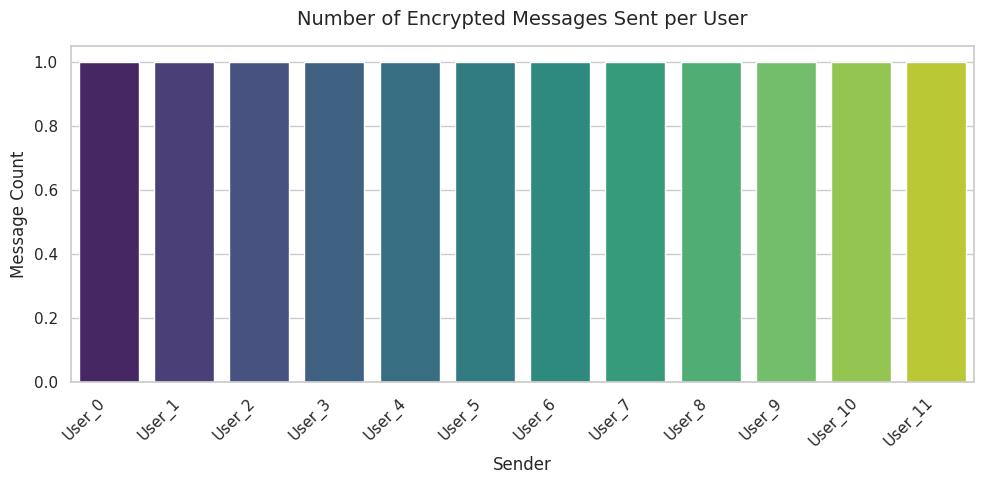

In [9]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

try:
    # Load JSON history
    with open('message_history.json', 'r') as f:
        history = json.load(f)

    # Load into DataFrame
    df = pd.DataFrame(history)

    # Group data
    sender_counts = df['sender'].value_counts().reset_index()
    sender_counts.columns = ['Sender', 'Message Count']

    # Plot
    plt.figure(figsize=(10, 5))
    sns.set_theme(style="whitegrid")

    ax = sns.barplot(
        x='Sender',
        y='Message Count',
        data=sender_counts,
        palette='viridis',
        hue='Sender',
        legend=False
    )

    plt.title('Number of Encrypted Messages Sent per User', fontsize=14, pad=15)
    plt.xlabel('Sender', fontsize=12)
    plt.ylabel('Message Count', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred while generating the plot: {e}")

## Improved Security: Dynamic Salts
Here is how you can refactor the functions to use a cryptographically secure random salt for every encryption. Notice how the salt is prepended to the ciphertext during encryption, and extracted from the start of the payload during decryption.

In [7]:
import os
from cryptography.fernet import Fernet
import base64
from cryptography.hazmat.primitives import hashes
from cryptography.hazmat.primitives.kdf.pbkdf2 import PBKDF2HMAC

def generate_key_from_password_dynamic(password: str, salt: bytes) -> bytes:
    """Derives a cryptographic key from a password and a unique, dynamic salt."""
    kdf = PBKDF2HMAC(
        algorithm=hashes.SHA256(),
        length=32,
        salt=salt,
        iterations=100000
    )
    return base64.urlsafe_b64encode(kdf.derive(password.encode()))

def encrypt_message_dynamic(message: str, password: str) -> str:
    if not message or not password:
        return "Error: Message and Password are required!"
    try:
        # 1. Generate a unique 16-byte random salt
        salt = os.urandom(16)

        # 2. Derive the key using this dynamic salt
        key = generate_key_from_password_dynamic(password, salt)
        fernet = Fernet(key)

        # 3. Encrypt the message
        encrypted_bytes = fernet.encrypt(message.encode())

        # 4. Combine salt + ciphertext. We encode both together in base64 so it can be transmitted easily
        combined_payload = salt + encrypted_bytes
        return base64.b64encode(combined_payload).decode('utf-8')
    except Exception as e:
        return f"Encryption failed: {str(e)}"

def decrypt_message_dynamic(encrypted_payload_b64: str, password: str) -> str:
    if not encrypted_payload_b64 or not password:
        return "Error: Encrypted text and Password are required!"
    try:
        # 1. Decode the combined payload
        combined_payload = base64.b64decode(encrypted_payload_b64.encode('utf-8'))

        # 2. Extract the first 16 bytes as the unique salt, and the rest as the ciphertext
        salt = combined_payload[:16]
        encrypted_bytes = combined_payload[16:]

        # 3. Re-derive the key using the extracted salt
        key = generate_key_from_password_dynamic(password, salt)
        fernet = Fernet(key)

        # 4. Decrypt the message
        decrypted_bytes = fernet.decrypt(encrypted_bytes)
        return decrypted_bytes.decode()
    except Exception as e:
        return "Decryption failed: Invalid password or corrupted message."

# --- Quick Demo of the Dynamic Salt Code ---
test_password = "secure_password_123"
secret_message = "This message now uses a dynamic salt!"

# Encrypting twice yields completely different ciphertexts even with the same key/password
ciphertext_1 = encrypt_message_dynamic(secret_message, test_password)
ciphertext_2 = encrypt_message_dynamic(secret_message, test_password)

print("Ciphertext 1:", ciphertext_1)
print("Ciphertext 2:", ciphertext_2)
print("\nDecrypted from 1:", decrypt_message_dynamic(ciphertext_1, test_password))
print("Decrypted from 2:", decrypt_message_dynamic(ciphertext_2, test_password))

Ciphertext 1: w7BB9WiZLWuRtp36Rdk7BmdBQUFBQUJxNktreXJVVlNtOFZLOTM4RHB6VEF0bWUzdEpyR0ltNlRqMGFaZGt0bTlTaF90Q19DNXBVZWxzZ3BORF9BVGUtelQzbGNqdGZCbGhhYnFBbkhJRnVBdzRlXzBBVFJXTDhjcC00SXZuazc3bXo5WDJ4MWxKaTRMYWVRc0NuX3pPNFVwWm9r
Ciphertext 2: JwKnW+qW/IpwDmg2K6/W+mdBQUFBQUJxNktreXlQNl9QbnBCY09tcEJZSlkxRGNZZ29sWDhpejBhSVpRaGxJWE1UNEE2NUVDcWRSTmhWbmN4V0NQWFdHYUc1d0FuTnNpc2FlNjlBXzhEUEFMajFxNWZyWHllWUFYYUpMSnVSZFd3YU1WcVRya0ZXeEFsbHVGMmhnaEhnYmtIbnlU

Decrypted from 1: This message now uses a dynamic salt!
Decrypted from 2: This message now uses a dynamic salt!


### Extracting and Verifying the Salt from a Ciphertext

When we use `encrypt_message_dynamic`, the output is a Base64-encoded string representing a concatenated byte sequence:
$$\text{Combined Payload} = \text{Salt (16 bytes)} + \text{Fernet Ciphertext}$$

To verify and extract the salt, we must:
1. Decode the Base64 string back into raw bytes.
2. Slice the first 16 bytes to retrieve the salt.
3. Slice the remaining bytes to retrieve the actual message ciphertext.

In [10]:
import base64

def extract_and_verify_salt(encrypted_payload_b64: str):
    try:
        # 1. Decode the base64-encoded string back to raw bytes
        combined_payload_bytes = base64.b64decode(encrypted_payload_b64.encode('utf-8'))

        # 2. Extract the first 16 bytes (the salt)
        extracted_salt = combined_payload_bytes[:16]

        # 3. Extract the remaining bytes (the ciphertext)
        remaining_ciphertext = combined_payload_bytes[16:]

        print("--- Payload Extraction Results ---")
        print(f"Total Payload Length (Bytes): {len(combined_payload_bytes)}")
        print(f"Extracted Salt (Bytes):       {extracted_salt}")
        print(f"Extracted Salt (Hex representation): {extracted_salt.hex()}")
        print(f"Extracted Salt Length (Should be 16): {len(extracted_salt)} bytes")
        print(f"Remaining Ciphertext Length:   {len(remaining_ciphertext)} bytes")

        return extracted_salt
    except Exception as e:
        print(f"Failed to extract salt: {e}")
        return None

# Let's extract and verify the salt from the first test ciphertext we generated earlier
extracted = extract_and_verify_salt(ciphertext_1)

--- Payload Extraction Results ---
Total Payload Length (Bytes): 156
Extracted Salt (Bytes):       b'\xc3\xb0A\xf5h\x99-k\x91\xb6\x9d\xfaE\xd9;\x06'
Extracted Salt (Hex representation): c3b041f568992d6b91b69dfa45d93b06
Extracted Salt Length (Should be 16): 16 bytes
Remaining Ciphertext Length:   140 bytes


### Decrypting the DataFrame column using pandas
We will decrypt the entire `encrypted_payload` column in the existing DataFrame `df` using `test_password`.

In [11]:
# Decrypt the encrypted_payload column in df
df['decrypted_payload'] = df['encrypted_payload'].apply(
    lambda x: decrypt_message_dynamic(x, test_password)
)

# Display the first few rows showing the decrypted content alongside the sender and timestamp
display(df[['timestamp', 'sender', 'decrypted_payload']].head())

,timestamp,sender,decrypted_payload
0,2026-11-02T15:15:22.968328,User_0,This message now uses a dynamic salt!
1,2026-11-02T15:15:22.968906,User_1,This message now uses a dynamic salt!
2,2026-11-02T15:15:22.969500,User_2,This message now uses a dynamic salt!
3,2026-11-02T15:15:22.969826,User_3,This message now uses a dynamic salt!
4,2026-11-02T15:15:22.970053,User_4,This message now uses a dynamic salt!


In [12]:
from google.colab import files

# Define output path
export_path = 'decrypted_history_dataframe.csv'

# Save the decrypted DataFrame (df) to CSV
df.to_csv(export_path, index=False)
print(f'[Success] DataFrame successfully exported to {export_path}')

# Trigger browser file download
files.download(export_path)

[Success] DataFrame successfully exported to decrypted_history_dataframe.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>